**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**01 | HARTH Data Foundation: Source Signals, Windowing and Statistical Features**

![HARTH data foundation workflow](../../images/01_consolidated_workflow.svg)

**Objective:** Examine a genuine HARTH v2.0 participant recording and develop a traceable workflow covering original signal inspection, time-safe label-pure windows and interpretable statistical features.

**Dataset:** Official NTNU AI Lab HARTH v2.0, pinned to the repository version. This integrated notebook uses `S023.csv`: two tri-axial accelerometers (lower back and thigh), a nominal sampling rate of 50 Hz and original acceleration values in **g**. The source differs from UCI HARTH v1.2.

**S023 source summary:** The original recording has **137,646 source samples** and **eight observed activity codes**. Time-safe segmentation produces **2,567 retained windows**, represented by **30 statistical features per window**. These observed counts describe this participant and are not fixed validation thresholds.

**Notebook scope:** This analysis combines source inspection, windowing and statistical features into one coherent sequence. It reads the original recording once for the main processing path, audits the source schema and labels, visualises genuine signals, creates 100-sample windows with a 50-sample stride, extracts five statistical features per channel and exports source-aligned tables and figures in `wearable_activity_recognition/output/`.

**Evaluation boundary:** S023 is used here only for the original exploratory demonstration. It was later among the two reserved HARTH assessment subjects and had already been inspected descriptively; therefore, later same-study held-out results must **not** be described as strictly blind or external. The multi-participant Development cohort is analysed separately.

**Reading order:** source file and schema → recorded activity labels → genuine signals → time-safe windows → retained activity support → example window → 30 statistical features → activity-level RMS exploration → saved outputs.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4),
)

# ----------------------- 4. Shared and Study Utilities -----------------------
from core.data_inspection import inspect_data, plot_signal
from core.signal_preprocessing import create_signal_windows
from core.feature_engineering import extract_signal_features
from core.output_download import download_outputs_from_colab
from harth_data import (
    ACTIVITY_NAMES, SENSOR_COLUMNS, ensure_harth_sample, load_harth_subject,
)

# ------------------- 5. Output Directory and Setup Summary -------------------
data_dir = root / "data" / "raw" / "harth_v2"
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)

SUBJECT_ID = "S023"
SAMPLING_RATE = 50
WINDOW_SIZE = 100
STEP_SIZE = 50
FEATURE_METHODS = [
    "mean", "std", "rms", "peak_to_peak", "waveform_length",
]

print("Source:", f"HARTH v2.0 / {SUBJECT_ID}.csv")
print("Outputs:", output_dir)
print("Windowing:", WINDOW_SIZE, "samples, stride", STEP_SIZE)
print("Statistical features:", FEATURE_METHODS)


Repository up to date.
Source: HARTH v2.0 / S023.csv
Outputs: /content/human-movement-intelligence/wearable_activity_recognition/output
Windowing: 100 samples, stride 50
Statistical features: ['mean', 'std', 'rms', 'peak_to_peak', 'waveform_length']


**02. Retrieve and Inspect the Original HARTH Recording**

The study adapter reuses `data/raw/harth_v2/S023.csv` if it is already present and nonempty. Otherwise it downloads the file from the official pinned source. A short raw-header inspection preserves the original column inventory without reading the full CSV twice. The full recording is then loaded once through the existing HARTH adapter, which parses timestamps and validates the six accelerometer channels and source labels.

The original recording has one annotated activity label per timestamp. This section reports the *observed* number of records and activities; record counts are descriptive rather than fixed validation thresholds.

In [3]:
# ================= 02. Retrieve and Inspect Original Source ==================

# -------------------- 1. Source File and Original Schema ---------------------
csv_path = ensure_harth_sample(data_dir, subject=SUBJECT_ID)
source_header = pd.read_csv(csv_path, nrows=5)
print("Original file:", csv_path)
print("Original source columns:", source_header.columns.tolist())
display(source_header)

# ----------------------- 2. Validated Continuous Data ------------------------
data, channel_names = load_harth_subject(csv_path)
inspect_data(data, name=f"HARTH {SUBJECT_ID}: validated continuous recording")
print("Six accelerometer channels:", channel_names)
print("Sampling frequency (nominal):", SAMPLING_RATE, "Hz")
print("Original activity codes:", sorted(data["label"].unique().tolist()))

# ------------------------ 3. Source Coverage Summary -------------------------
observed_intervals = data["timestamp"].diff().dt.total_seconds().dropna()
source_summary = pd.DataFrame([{
    "subject_id": SUBJECT_ID,
    "source_file": csv_path.name,
    "recorded_samples": len(data),
    "source_columns": len(source_header.columns),
    "acceleration_channels": len(channel_names),
    "missing_values": int(data.isna().sum().sum()),
    "nominal_sampling_frequency_hz": SAMPLING_RATE,
    "median_observed_interval_s": float(observed_intervals.median()),
    "observed_activity_codes": data["label"].nunique(),
}])
display(source_summary)
source_summary.to_csv(output_dir / "01_source_inspection_summary.csv", index=False)


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S023.csv
Original file: /content/human-movement-intelligence/data/raw/harth_v2/S023.csv
Original source columns: ['timestamp', 'back_x', 'back_y', 'back_z', 'thigh_x', 'thigh_y', 'thigh_z', 'label']


,timestamp,back_x,back_y,back_z,thigh_x,thigh_y,thigh_z,label
0,2019-01-12 00:00:00.000,-1.108887,0.057861,-0.076904,-1.396973,-0.327148,-0.141846,6
1,2019-01-12 00:00:00.020,-1.054932,0.073486,-0.113770,-1.363281,-0.386475,-0.321533,6
2,2019-01-12 00:00:00.040,-0.911377,-0.007568,-0.160156,-1.080078,-0.096680,-0.354492,6
3,2019-01-12 00:00:00.060,-0.865234,-0.062500,-0.176025,-1.012939,0.163574,-0.229736,6
4,2019-01-12 00:00:00.080,-0.992920,-0.026123,-0.178467,-0.989014,0.199951,-0.088379,6


HARTH subject S023: 137,646 rows, 6 sensors

===== HARTH S023: validated continuous recording =====
Rows: 137646 | Columns: 8
Missing values: 0
Columns: timestamp, back_x, back_y, back_z, thigh_x, thigh_y, thigh_z, label
              timestamp    back_x    back_y    back_z   thigh_x   thigh_y   thigh_z  label
2019-01-12 00:00:00.000 -1.108887  0.057861 -0.076904 -1.396973 -0.327148 -0.141846      6
2019-01-12 00:00:00.020 -1.054932  0.073486 -0.113770 -1.363281 -0.386475 -0.321533      6
2019-01-12 00:00:00.040 -0.911377 -0.007568 -0.160156 -1.080078 -0.096680 -0.354492      6
2019-01-12 00:00:00.060 -0.865234 -0.062500 -0.176025 -1.012939  0.163574 -0.229736      6
2019-01-12 00:00:00.080 -0.992920 -0.026123 -0.178467 -0.989014  0.199951 -0.088379      6
Six accelerometer channels: ['back_x', 'back_y', 'back_z', 'thigh_x', 'thigh_y', 'thigh_z']
Sampling frequency (nominal): 50 Hz
Original activity codes: [1, 2, 3, 4, 5, 6, 7, 8]


,subject_id,source_file,recorded_samples,source_columns,acceleration_channels,missing_values,nominal_sampling_frequency_hz,median_observed_interval_s,observed_activity_codes
0,S023,S023.csv,137646,8,6,0,50,0.02,8


**03. Explore Original Activity Labels and Source Signals**

The recorded activity distribution is calculated from the original source samples, **before** segmentation. The lower-back X/Y/Z traces show genuine acceleration (g) without filtering, interpolation or scaling. Sample counts describe this participant's recording, not independent people.

Original codes are retained. A label without a documented description is shown as an unidentified source code rather than silently assigned to a different activity.

,label,activity,samples
0,1,Walking,70601
1,2,Running,22391
2,3,Shuffling,2071
3,4,Stairs ascending,3194
4,5,Stairs descending,2291
5,6,Standing,7455
6,7,Sitting,13059
7,8,Lying,16584


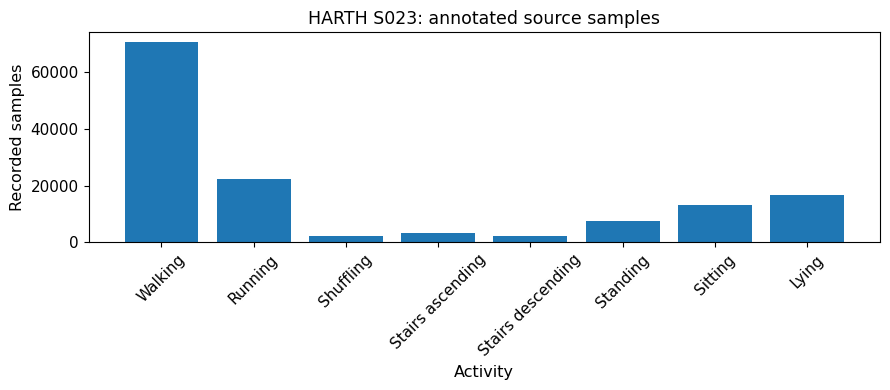

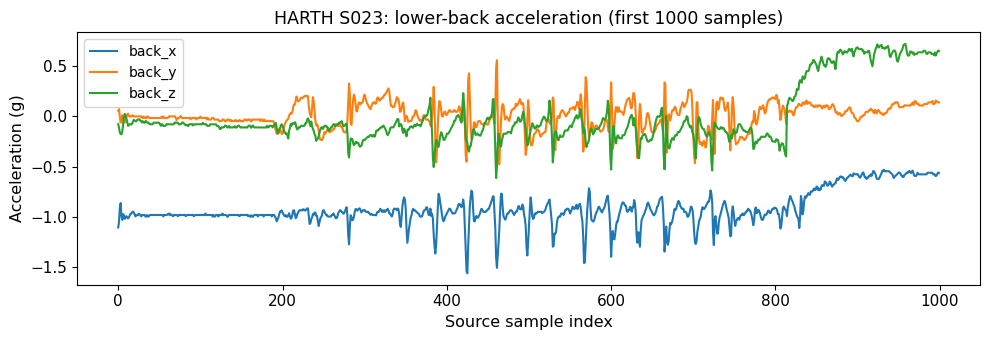

In [4]:
# ============== 03. Original Activity and Acceleration Signals ===============

# --------------------- 1. Recorded Activity Distribution ---------------------
original_counts = data["label"].value_counts().sort_index()
activity_table = pd.DataFrame({
    "label": original_counts.index.astype(int),
    "activity": [
        ACTIVITY_NAMES.get(int(code), f"Unmapped source code {int(code)}")
        for code in original_counts.index
    ],
    "samples": original_counts.to_numpy(),
})
display(activity_table)
activity_table.to_csv(output_dir / "01_activity_distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(activity_table["activity"], activity_table["samples"])
ax.set(
    title=f"HARTH {SUBJECT_ID}: annotated source samples",
    xlabel="Activity", ylabel="Recorded samples",
)
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
save_figure(fig, output_dir / "01_activity_distribution.png")
plt.show()

# ------------------------ 2. Genuine Unscaled Signal -------------------------
n_points = min(1000, len(data))
original_signal = data.iloc[:n_points][channel_names[:3]].to_numpy().T
fig = plot_signal(
    original_signal,
    title=f"HARTH {SUBJECT_ID}: lower-back acceleration (first {n_points} samples)",
    channel_names=channel_names[:3],
)
fig.axes[0].set_xlabel("Source sample index")
fig.axes[0].set_ylabel("Acceleration (g)")
save_figure(fig, output_dir / "01_acceleration_signals.png")
plt.show()


**04. Build Time-Safe, Label-Pure Signal Windows**

At 50 Hz, a 100-sample window represents two seconds. The 50-sample stride creates 50% overlap. The shared `create_signal_windows` function excludes a candidate if its labels differ or its timestamps contain a non-positive or excessive gap (above 1.5 times the expected sample period).

A single segmentation pass creates the aligned windows. The returned tensor is `(windows, 6 channels, 100 samples)` and `window_info` retains original source-row indices and participant identity. No scaling or model fitting occurs.

In [5]:
# ================== 04. Generate Label-Pure Signal Windows ===================

# ------------------- 1. Apply the Original Windowing Rules -------------------
X_windows, y_windows, window_info = create_signal_windows(
    signals=data[channel_names].to_numpy(),
    labels=data["label"].to_numpy(),
    window_size=WINDOW_SIZE,
    step_size=STEP_SIZE,
    timestamps=data["timestamp"],
    sampling_rate=SAMPLING_RATE,
    min_label_purity=1.0,
    subject_id=SUBJECT_ID,
)

# ----------------- 2. Verify Essential Array Correspondence ------------------
if not (len(X_windows) == len(y_windows) == len(window_info)):
    raise ValueError("Window arrays, labels and source metadata are misaligned.")
if not len(X_windows):
    raise ValueError("No time-safe, single-activity windows were retained.")

print("Signal windows:", X_windows.shape)
print("Window labels:", y_windows.shape)
print("Source metadata rows:", len(window_info))
display(window_info.head(8))

# ------------------------ 3. Save the Current Windows ------------------------
window_info.to_csv(output_dir / "01_window_metadata.csv", index=False)
np.savez_compressed(
    output_dir / "01_label_pure_windows.npz",
    X_windows=X_windows,
    y_windows=y_windows,
    channel_names=np.asarray(channel_names),
    window_size=np.int64(WINDOW_SIZE),
    step_size=np.int64(STEP_SIZE),
)
print("Saved source-aligned windows and metadata to:", output_dir)


Input signal: 137,646 samples, 6 channels
Candidate windows: 2,751
Retained windows: 2,567 | Shape: (2567, 6, 100)
Rejected candidates: 184
Signal windows: (2567, 6, 100)
Window labels: (2567,)
Source metadata rows: 2567


,subject_id,start_index,end_index_exclusive,label,label_purity
0,S023,0,100,6,1.0
1,S023,50,150,6,1.0
2,S023,100,200,6,1.0
3,S023,150,250,6,1.0
4,S023,200,300,6,1.0
5,S023,350,450,1,1.0
6,S023,400,500,1,1.0
7,S023,450,550,1,1.0


Saved source-aligned windows and metadata to: /content/human-movement-intelligence/wearable_activity_recognition/output


**05. Compare Activity Coverage Before and After Windowing**

Count the source samples and the retained *two-second windows* for each activity. These are different units and should not be interpreted as a direct retention percentage. Transitions, discontinuities and incomplete windows can change the relative activity support after segmentation.

**S023 activity support:** the 2,567 retained windows include 1,352 Walking windows, 441 Running windows, 7 Shuffling windows, 42 ascending-stairs windows and 26 descending-stairs windows. These counts indicate unequal coverage, not classifier performance.

,label,activity,source_samples,retained_windows
0,1,Walking,70601,1352
1,2,Running,22391,441
2,3,Shuffling,2071,7
3,4,Stairs ascending,3194,42
4,5,Stairs descending,2291,26
5,6,Standing,7455,114
6,7,Sitting,13059,257
7,8,Lying,16584,328


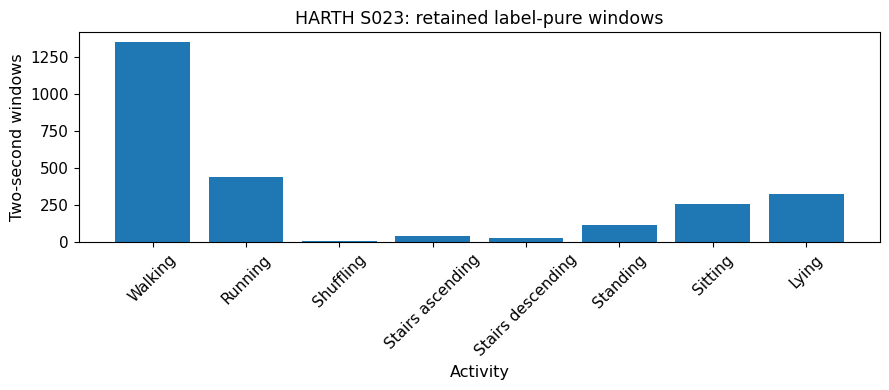

In [6]:
# ============== 05. Compare Source and Window Activity Support ===============

# --------------------- 1. Source and Window Label Counts ---------------------
window_counts = pd.Series(y_windows, name="label").value_counts().sort_index()
window_distribution = pd.DataFrame({
    "label": original_counts.index.astype(int),
    "activity": [
        ACTIVITY_NAMES.get(int(code), f"Unmapped source code {int(code)}")
        for code in original_counts.index
    ],
    "source_samples": original_counts.to_numpy(),
    "retained_windows": [
        int(window_counts.get(code, 0)) for code in original_counts.index
    ],
})
display(window_distribution)
window_distribution.to_csv(
    output_dir / "01_window_activity_support.csv", index=False
)

# ------------------------- 2. Retained Window Figure -------------------------
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(window_distribution["activity"], window_distribution["retained_windows"])
ax.set(
    title=f"HARTH {SUBJECT_ID}: retained label-pure windows",
    xlabel="Activity", ylabel="Two-second windows",
)
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
save_figure(fig, output_dir / "01_retained_activity_distribution.png")
plt.show()


**06. Inspect a Genuine Two-Second Signal Window**

This figure uses the **first eligible window**, not a hand-picked favourable example. The accelerometer values remain in g. The original sample indices, source annotation and label purity are shown alongside the plot.

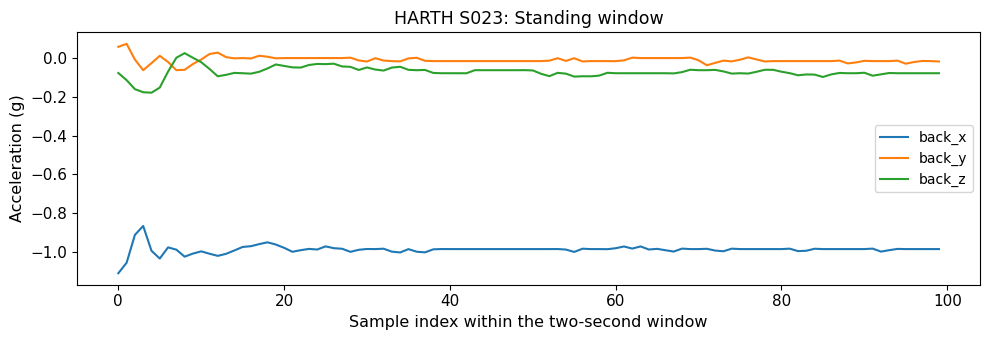

Original source samples: 0 to 99
Activity label: 6
Label purity: 1.0


In [7]:
# =================== 06. Visualise a Source-Aligned Window ===================

# ------------------------- 1. Original Window Trace --------------------------
example_index = 0
example_label = int(y_windows[example_index])
fig = plot_signal(
    X_windows[example_index, :3, :],
    title=(f"HARTH {SUBJECT_ID}: "
           f"{ACTIVITY_NAMES.get(example_label, str(example_label))} window"),
    channel_names=channel_names[:3],
)
fig.axes[0].set_xlabel("Sample index within the two-second window")
fig.axes[0].set_ylabel("Acceleration (g)")
save_figure(fig, output_dir / "01_example_window_signals.png")
plt.show()

# ----------------------- 2. Source Window Coordinates ------------------------
source_record = window_info.iloc[example_index]
print("Original source samples:", int(source_record["start_index"]), "to",
      int(source_record["end_index_exclusive"]) - 1)
print("Activity label:", example_label)
print("Label purity:", float(source_record["label_purity"]))


**07. Extract Thirty Interpretable Statistical Features**

Apply the same five predefined methods to each of the six acceleration channels: **mean**, **population standard deviation**, **root mean square (RMS)**, **peak-to-peak range** and **normalised waveform length** (mean absolute difference between adjacent samples).

This section reuses `X_windows` already produced in Section 04. It does **not** reload the source, rebuild a second window set or fit feature scaling. The resulting table contains 30 aligned per-window predictors and is exported together with the corresponding source-window metadata.

In [8]:
# =========== 07. Extract Statistical Features from Current Windows ===========

# --------------------- 1. Deterministic Window Features ----------------------
feature_table = extract_signal_features(
    X_windows,
    channel_names=channel_names,
    methods=FEATURE_METHODS,
)

# --------------------- 2. Align Features and Source Rows ---------------------
if len(feature_table) != len(window_info):
    raise ValueError("Statistical feature rows do not align with source windows.")
if not np.isfinite(feature_table.to_numpy()).all():
    raise ValueError("The statistical feature table contains non-finite values.")

print("Feature matrix:", feature_table.shape)
print("Example feature names:", feature_table.columns[:10].tolist())
feature_overview = inspect_data(
    feature_table, name=f"HARTH {SUBJECT_ID}: statistical feature matrix"
)
display(feature_table.head())

# ------------------- 3. Save Current Aligned Feature Table -------------------
feature_export = pd.concat(
    [
        window_info.reset_index(drop=True).add_prefix("window_"),
        pd.DataFrame({"source_label": y_windows}),
        feature_table.reset_index(drop=True),
    ],
    axis=1,
)
feature_export.to_csv(output_dir / "01_statistical_features.csv", index=False)
print("Saved aligned feature table:",
      output_dir / "01_statistical_features.csv")


Input windows: (2567, 6, 100)
Feature matrix: (2567, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Feature matrix: (2567, 30)
Example feature names: ['back_x__mean', 'back_x__std', 'back_x__rms', 'back_x__peak_to_peak', 'back_x__waveform_length', 'back_y__mean', 'back_y__std', 'back_y__rms', 'back_y__peak_to_peak', 'back_y__waveform_length']

===== HARTH S023: statistical feature matrix =====
Rows: 2567 | Columns: 30
Missing values: 0
Columns: back_x__mean, back_x__std, back_x__rms, back_x__peak_to_peak, back_x__waveform_length, back_y__mean, back_y__std, back_y__rms, back_y__peak_to_peak, back_y__waveform_length, back_z__mean, back_z__std, back_z__rms, back_z__peak_to_peak, back_z__waveform_length, thigh_x__mean, thigh_x__std, thigh_x__rms, thigh_x__peak_to_peak, thigh_x__waveform_length, thigh_y__mean, thigh_y__std, thigh_y__rms, thigh_y__peak_to_peak, thigh_y__waveform_length, thigh_z__mean, thigh_z__std, thigh_z__rms, thigh_z__peak_to_peak, thigh_z__waveform_length
 

,back_x__mean,back_x__std,back_x__rms,back_x__peak_to_peak,back_x__waveform_length,back_y__mean,back_y__std,back_y__rms,back_y__peak_to_peak,back_y__waveform_length,...,thigh_y__mean,thigh_y__std,thigh_y__rms,thigh_y__peak_to_peak,thigh_y__waveform_length,thigh_z__mean,thigh_z__std,thigh_z__rms,thigh_z__peak_to_peak,thigh_z__waveform_length
0,-0.986616,0.022918,0.986882,0.243653,0.010584,-0.009849,0.017442,0.020030,0.135986,0.008131,...,-0.060723,0.062084,0.086843,0.586426,0.023413,0.043762,0.074973,0.086810,0.516846,0.022024
1,-0.985547,0.005812,0.985564,0.033936,0.004520,-0.022791,0.014661,0.027099,0.052734,0.005558,...,-0.049792,0.015131,0.052041,0.062744,0.007899,0.072261,0.021348,0.075348,0.095215,0.010846
2,-0.986951,0.012642,0.987032,0.109864,0.006081,-0.046245,0.035022,0.058010,0.175048,0.007011,...,-0.036003,0.014824,0.038936,0.092041,0.006991,0.074793,0.021476,0.077815,0.109863,0.006853
3,-0.984619,0.031933,0.985137,0.177246,0.014318,-0.011624,0.114468,0.115057,0.443360,0.018283,...,-0.040164,0.065943,0.077211,0.365723,0.021169,0.066587,0.077204,0.101953,0.404053,0.022942
4,-0.980664,0.053464,0.982120,0.370362,0.023203,0.005269,0.143135,0.143232,0.565918,0.033534,...,-0.037969,0.124625,0.130280,0.628906,0.045156,-0.053779,0.151463,0.160728,0.598389,0.042086


Saved aligned feature table: /content/human-movement-intelligence/wearable_activity_recognition/output/01_statistical_features.csv


**08. Explore RMS Features Across Annotated Activities**

The scatter plot compares lower-back and thigh X-axis RMS, while the boxplot shows the distribution of lower-back X-axis RMS within each observed activity. These figures are descriptive feature analyses, **not classifier predictions**. Their differences reflect the single inspected participant and do not establish unseen-participant performance.

**S023 example:** The mean lower-back X-axis RMS was approximately 1.3657 g for Running and 0.0270 g for Lying. This observation describes the single-participant feature table and should not be interpreted as a general class-separation result.

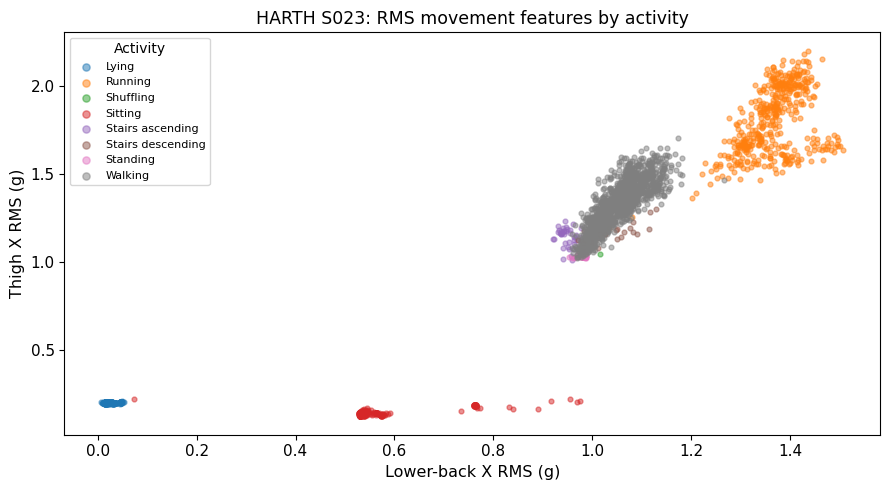

,retained_windows,mean_back_x_rms,mean_thigh_x_rms
activity,,,
Walking,1352,1.051158,1.323975
Running,441,1.365743,1.806327
Lying,328,0.027020,0.200489
Sitting,257,0.580205,0.144822
Standing,114,0.980754,1.036934
Stairs ascending,42,0.950649,1.141175
Stairs descending,26,1.039741,1.167314
Shuffling,7,0.983734,1.049556


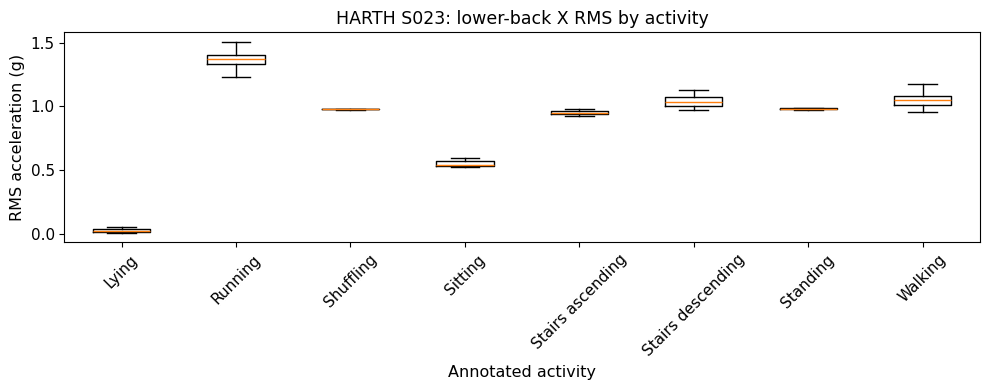

In [9]:
# =============== 08. Visualise Activity-Dependent RMS Features ===============

# ------------------------ 1. Source-Labelled RMS Data ------------------------
rms_data = feature_table[["back_x__rms", "thigh_x__rms"]].copy()
rms_data["activity"] = [
    ACTIVITY_NAMES.get(int(label), f"Unmapped source code {int(label)}")
    for label in y_windows
]

# ---------------------------- 2. RMS Scatter Plot ----------------------------
fig, ax = plt.subplots(figsize=(9, 5))
for activity, subset in rms_data.groupby("activity", sort=True):
    ax.scatter(
        subset["back_x__rms"], subset["thigh_x__rms"],
        s=12, alpha=0.5, label=activity,
    )
ax.set(
    title=f"HARTH {SUBJECT_ID}: RMS movement features by activity",
    xlabel="Lower-back X RMS (g)", ylabel="Thigh X RMS (g)",
)
ax.legend(title="Activity", fontsize=8, markerscale=1.5)
fig.tight_layout()
save_figure(fig, output_dir / "01_rms_activity_scatter.png")
plt.show()

# -------------------- 3. Activity-Level RMS Measurements ---------------------
rms_summary = (
    rms_data.groupby("activity", sort=True)
    .agg(
        retained_windows=("back_x__rms", "size"),
        mean_back_x_rms=("back_x__rms", "mean"),
        mean_thigh_x_rms=("thigh_x__rms", "mean"),
    )
    .sort_values("retained_windows", ascending=False)
)
display(rms_summary)
rms_summary.reset_index().to_csv(
    output_dir / "01_rms_activity_summary.csv", index=False
)

# --------------------- 4. RMS Distributions by Activity ----------------------
activity_groups = list(rms_data.groupby("activity", sort=True))
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(
    [group["back_x__rms"].to_numpy() for _, group in activity_groups],
    tick_labels=[activity for activity, _ in activity_groups],
    showfliers=False,
)
ax.set(
    title=f"HARTH {SUBJECT_ID}: lower-back X RMS by activity",
    xlabel="Annotated activity", ylabel="RMS acceleration (g)",
)
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
save_figure(fig, output_dir / "01_rms_activity_boxplot.png")
plt.show()


**09. Export Windowing Summary and Research Outputs**

Summarise the sampling rate, window length, overlap, purity requirement, original sample count and retained window count in `01_windowing_summary.csv`. These values document the actual segmentation recipe and resulting dataset without requiring any fixed historical counts.

The `01_` CSV tables retain source activity distributions, aligned window metadata, statistical features and RMS summaries. PNG files provide the associated signal and feature visualisations. `01_label_pure_windows.npz` contains the numerical window tensor and labels for reuse where needed; the repository's `.gitignore` excludes NPZ files, so this array must be retained separately when a later calculation depends on it.

The packaging helper collects files with the `01_` prefix for optional manual retrieval from Colab. The CSV feature table is the direct input to the later S023 exploratory reuse.


In [10]:
# ================== 09. Summarise and Package Stage Outputs ==================

# -------------------- 1. Current Windowing Configuration ---------------------
window_summary = pd.DataFrame([{
    "subject_id": SUBJECT_ID,
    "sampling_rate_hz": SAMPLING_RATE,
    "window_size_samples": WINDOW_SIZE,
    "step_size_samples": STEP_SIZE,
    "overlap_fraction": 1 - STEP_SIZE / WINDOW_SIZE,
    "label_purity_threshold": 1.0,
    "source_rows": len(data),
    "retained_windows": len(X_windows),
    "signal_channels": len(channel_names),
    "statistical_features": feature_table.shape[1],
}])
window_summary.to_csv(output_dir / "01_windowing_summary.csv", index=False)
display(window_summary)

# ------------------------- 2. Manual Colab Download --------------------------
download_outputs_from_colab(
    folder="wearable_activity_recognition/output", stage="01"
)


,subject_id,sampling_rate_hz,window_size_samples,step_size_samples,overlap_fraction,label_purity_threshold,source_rows,retained_windows,signal_channels,statistical_features
0,S023,50,100,50,0.5,1.0,137646,2567,6,30


------------------------------------------------------------------------
Notebook stage: 01
Files packaged: 14
  + 01_acceleration_signals.png
  + 01_activity_distribution.csv
  + 01_activity_distribution.png
  + 01_example_window_signals.png
  + 01_label_pure_windows.npz
  + 01_retained_activity_distribution.png
  + 01_rms_activity_boxplot.png
  + 01_rms_activity_scatter.png
  + 01_rms_activity_summary.csv
  + 01_source_inspection_summary.csv
  + 01_statistical_features.csv
  + 01_window_activity_support.csv
  + 01_window_metadata.csv
  + 01_windowing_summary.csv
Download ZIP from Colab Contents: /content/wearable_activity_recognition_Stage_01_Outputs.zip


**10. Scientific Interpretation and Research Boundaries**

The S023 recording contains **137,646 source samples**, from which the defined two-second, label-pure segmentation yields **2,567 windows**. Five deterministic statistics computed on each of six original acceleration channels produce an aligned **30-feature** representation. Window metadata retain participant identity and source-sample indices.

**Interpretation:** Source-sample counts and overlapping window counts represent different observation units. The descriptive RMS comparison illustrates differences among annotated activities for this participant; it does not measure classifier accuracy or generalisation across people.

**Methodological boundary:** Original acceleration remains in **g**, without filtering, fitted scaling or model-specific transformations. S023 is a descriptive example rather than a participant-disjoint Development sample. Because S023 and S032 were previously inspected, their later same-collection assessment cannot be presented as strictly blind or external validation.

**Data reuse:** The exported statistical-feature and window-metadata tables provide an interpretable reference for source-level exploration. Multi-participant Development analyses require their separately specified participant groups and must not treat S023 as Development training data.
